<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QNN_QuantumActivation_IDS_Laxminarayana2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum-assisted activation for intrusion detection: Laxminarayana et al. (2024) step by step

**Paper.** N. Laxminarayana, N. Mishra, P. Tiwari, S. Garg, B. K. Behera, A. Farouk, *Quantum-Assisted Activation for Supervised Learning in Healthcare-Based Intrusion Detection Systems*, IEEE Transactions on Artificial Intelligence, vol. 5, no. 3, pp. 977-984, March 2024 (published online 1 July 2022). DOI: [10.1109/TAI.2022.3187676](https://doi.org/10.1109/TAI.2022.3187676).

> **Retraction notice (stated on the first page of the PDF).** IEEE retracted the article because a co-author was, at the time of publication, prohibited from publishing with IEEE (an authorship-policy reason). The notice does not say that the experiments were wrong, and the other authors disagreed with the retraction. This notebook therefore treats the paper as a *method description to test*, not as evidence: every number is recomputed here and compared honestly.

**What this notebook does.** The paper replaces the activation function of a small classical neural network by a *quantum circuit* (8 qubits: Hadamards, one `RY` rotation per qubit that encodes the data, pairs of controlled-`RY` gates that entangle neighbouring qubits, expectation value of `Z` on all qubits). The network is trained end to end on the KDD Cup 1999 intrusion data. Here we

1. download the KDD Cup 99 10 % file, build the paper's 23-class problem and look at the real data,
2. build the quantum layer as a PennyLane circuit, draw it, and prove that a fast exact statevector simulator used for training gives the same numbers as the real circuit (and as a Qiskit circuit),
3. train the paper's two architectures (ARCH1 with one quantum layer, ARCH2 with two) in PyTorch with Adam, plus controls: the same network with a classical activation, a network without any activation, and Random Forest / SVC on identical inputs,
4. repeat the paper's "accuracy versus number of quantum layers" experiment, and
5. print a claim-by-claim comparison with the paper, followed by a critical reading and exercises.

**How to run.** Google Colab, CPU runtime, *Runtime > Run all*. The committed outputs come from one complete run with `FAST_MODE = False` (about 70 minutes on a shared laptop CPU, three seeds, 15 epochs, a depth sweep to 10 quantum layers). With `FAST_MODE = True` the notebook takes about five minutes; both budgets are listed in the configuration cell. No GPU, no account, no token is needed (KDD99 is public).

**What you get at the end.** Executed dataset plots, the executed circuit drawing, learning curves, confusion matrices, a table of the paper's claims next to this notebook's numbers with a verdict for each, and a discussion of what the quantum layer really computes.

## The paper in one page

* **Problem.** Network intrusion detection for hospital networks (Fig. 1 of the paper is a schematic of a hybrid neural IDS sitting at the gateway of a hospital network). The experiments use no healthcare traffic: they use the generic **KDD Cup 1999** connection records.
* **Decision.** Multi-class classification of a connection record into the 23 labels of the KDD99 10 % training file (normal plus 22 attack types in four families: DoS, probe, R2L, U2R).
* **Method.** A hybrid classical-quantum network. *ARCH1*: `Input(120) -> Dense(8) -> QuantumLayer(8 qubits) -> Dense(10) -> Dense(23, softmax)`, 1823 trainable parameters. *ARCH2*: `Input(120) -> Dense(10) -> Dense(8) -> Quantum -> Quantum -> Dense(23, softmax)`, 2529 trainable parameters.
* **Quantum layer ("quantum-assisted activation").** For every sample of a batch of `k = 64` records: start in the uniform superposition (Hadamard on every qubit), encode the 8 inputs with `RY(x_i * pi)`, entangle with controlled-`RY(w * 2 pi)` gates on qubit pairs, measure the expectation of `Z (x) Z (x) ... (x) Z`, and map the single number to 8 outputs with fixed scaling factors. The trainable weights are `W` of shape `k x n` (batch size times qubits).
* **Training.** Keras, Adam, learning rate 0.01, decay 0.001, categorical cross-entropy, batch 64; the text says 1000 epochs, the learning curve in Fig. 5 shows 15 epochs.
* **Claims.** (i) the quantum activation captures the patterns of KDD99 with fewer parameters than classical RNN/CNN/LSTM models (Table II and Fig. 3: the numbers of Table II are an image that is not machine readable in the PDF); (ii) the parameter counts of Table III; (iii) Fig. 5: training accuracy rises from about 0.79 to about 0.915 and the loss falls from about 0.50 to about 0.09 over 15 epochs; (iv) Fig. 4: test accuracy is about 0.995 with one quantum layer, about 0.98-0.99 for 2 to 5 layers and falls to about 0.95 for 8 to 10 layers (values read off the plot); (v) the activation "cannot be efficiently simulated on classical computers".

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | KDD99, 120 features after preprocessing, 23 classes | KDD99 10 % file (figshare mirror of scikit-learn); one-hot of `protocol_type`, `service`, `flag` plus the numeric columns; **our input width is printed in Section 2** (it is 118, not 120, because the paper's exact encoding is not given) |
| Train / test split | not given | `# CHOICE:` stratified random subsample of the de-duplicated records (the paper itself notes the duplicates); sizes in the configuration cell |
| Scaling | not given | `# CHOICE:` `log1p` for heavy-tailed numeric columns, then `StandardScaler`, fitted on the training split only |
| Quantum circuit | H, `RY(x_i pi)`, pairwise controlled-`RY(w 2 pi)`, `Z^(x)n` | same; pairs are `(0,1),(2,3),(4,5),(6,7)` with one controlled-`RY` in each direction (this is what Fig. 2 of the paper shows) |
| Weights `W` | `k x n`, `k` = batch size (this is what gives 512 parameters per quantum layer) | same ("paper" variant: row `j` of `W` is used for the `j`-th record of every batch); we also run a *shared* `1 x n` weight variant because tying parameters to the position of a record inside a batch is unusual |
| Output map `f` | "linear function ... different scaling factors" | `# CHOICE:` fixed (non-trainable) factors `linspace(0.5, 2.0, 8)` |
| Weight initialisation | not given | `# CHOICE:` `W ~ U(0, 1)`; PyTorch default for the dense layers |
| Optimiser | Adam, lr 0.01, decay 0.001, batch 64 | same; decay implemented as `lr / (1 + 0.001 * step)` as in legacy Keras |
| Epochs | 1000 (text) / 15 (Fig. 5) | 15 in the full run, fewer in `FAST_MODE` (CPU budget) |
| Framework | TensorFlow Keras + Qiskit Aer | PyTorch + PennyLane (circuit) + an exact PyTorch statevector simulator for speed |
| Healthcare link | title and motivation only | no healthcare data is used by the paper either |

In [1]:
# Colab installs (pinned to the versions this notebook was tested with). Skipped when the packages are already there.
import importlib, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
def _missing(mod):
    try:
        importlib.import_module(mod); return False
    except Exception:
        return True
if IN_COLAB or _missing("pennylane") or _missing("qiskit"):
    # A session restart may be required after the first install on Colab.
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "qiskit==2.5.2", "pylatexenc"], check=False)


In [2]:
# ---------------- configuration (every tunable constant lives here) ----------------
FAST_MODE = False        # True: class demo (< 10 min on a laptop CPU). False: full budgets below.
SEED      = 42             # CHOICE: the paper reports no seed
N_QUBITS  = 8              # paper: 8-node quantum layer
BATCH_SIZE = 64            # paper: batch 64 (also the number of rows of the paper's weight matrix W)
LEARNING_RATE = 0.01       # paper: Adam, lr 0.01
LR_DECAY      = 0.001      # paper: decay 0.001 (legacy Keras: lr_t = lr / (1 + decay * step))
HIDDEN_DENSE  = 10         # paper: Dense(10) after the quantum layer (ARCH1)
N_CLASSES     = 23         # paper: softmax of 23 nodes
DEDUP = True               # CHOICE: drop exact duplicate records before sampling (about 75 % of the 10 % file)
DATA_DIR = "data"          # downloads are cached here
IBM_TOKEN = ""             # not used: the paper simulates the circuit, no real hardware is needed
TOL_ACC = 0.02             # a claim is "reproduced" when within 2 accuracy points

if FAST_MODE:
    N_TRAIN, N_TEST = 4000, 4000
    EPOCHS          = 3          # paper Fig. 5 shows 15
    SEEDS           = [42]
    SWEEP_LAYERS    = [1, 2, 3]  # paper Fig. 4 shows 1..10
    SWEEP_EPOCHS    = 2
    SVC_MAX_TRAIN   = 4000
else:
    N_TRAIN, N_TEST = 20000, 15000
    EPOCHS          = 15
    SEEDS           = [42, 43, 44]
    SWEEP_LAYERS    = list(range(1, 11))
    SWEEP_EPOCHS    = 3
    SVC_MAX_TRAIN   = 10000
KDD_URLS = ["https://ndownloader.figshare.com/files/5976042",                                    # scikit-learn's mirror of the 10 % file
            "http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz"]               # original UCI location
print("FAST_MODE =", FAST_MODE, "| train/test:", N_TRAIN, N_TEST, "| epochs:", EPOCHS, "| seeds:", SEEDS, "| sweep layers:", SWEEP_LAYERS)


FAST_MODE = False | train/test: 20000 15000 | epochs: 15 | seeds: [42, 43, 44] | sweep layers: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [3]:
import os, time, warnings, math
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import qiskit
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_score, recall_score
from IPython.display import display

torch.set_num_threads(1)
torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("torch", torch.__version__, "| pennylane", qml.__version__, "| qiskit", qiskit.__version__, "| numpy", np.__version__)


torch 2.14.1+cpu | pennylane 0.45.1 | qiskit 2.5.2 | numpy 2.5.4


## 1. Download the KDD Cup 99 data and attach the original labels

The 10 % training file of KDD Cup 1999 (494,021 connection records, 41 features, a label such as `smurf.` or `normal.`) is downloaded from the figshare mirror used by scikit-learn, with the original UCI location and scikit-learn's own downloader as fallbacks. The four attack families (DoS, probe, R2L, U2R) are mapped from the label names; the paper's 23 outputs are exactly the 23 labels of this file.

In [4]:
KDD_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
               "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
               "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
               "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
               "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
               "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
               "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label"]
ALL_FEATURES = [c for c in KDD_COLUMNS if c != "label"]
CAT_COLS = ["protocol_type", "service", "flag"]
NUM_COLS = [c for c in ALL_FEATURES if c not in CAT_COLS]

FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop"]: FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep"]: FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy"]: FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl"]: FAMILY[a] = "U2R"
FAMILY_ORDER = ["normal", "DoS", "Probe", "R2L", "U2R"]
FAMILY_COLOR = {"normal": "tab:blue", "DoS": "tab:red", "Probe": "tab:orange", "R2L": "tab:green", "U2R": "tab:purple"}

def download(path, urls):
    import requests
    for url in urls:
        try:
            r = requests.get(url, timeout=180); r.raise_for_status()
            open(path, "wb").write(r.content); print("downloaded", os.path.basename(path), "from", url.split("/")[2]); return True
        except Exception as e:
            print("failed:", url, type(e).__name__)
    return False

def load_kdd():
    path = os.path.join(DATA_DIR, "kddcup.data_10_percent.gz")
    if os.path.exists(path) or download(path, KDD_URLS):
        return pd.read_csv(path, header=None, names=KDD_COLUMNS, compression="gzip")
    from sklearn.datasets import fetch_kddcup99                                   # last resort: scikit-learn's own downloader
    d = fetch_kddcup99(percent10=True, as_frame=True, data_home=DATA_DIR).frame
    d = d.rename(columns={"labels": "label"})
    for c in CAT_COLS + ["label"]:
        d[c] = d[c].astype(str).str.replace("b'", "").str.rstrip("'")
    return d[KDD_COLUMNS]

t0 = time.time()
raw = load_kdd()
raw["label"] = raw["label"].astype(str).str.rstrip(".")
raw["family"] = raw["label"].map(FAMILY)
assert raw["family"].notna().all(), sorted(set(raw.label) - set(FAMILY))
LABELS = sorted(raw["label"].unique())                    # the paper's 23 output nodes
assert len(LABELS) == N_CLASSES, len(LABELS)
LABEL_ID = {l: i for i, l in enumerate(LABELS)}
print(f"KDD99 10 % file: {raw.shape[0]:,} records x {len(ALL_FEATURES)} features + label ({time.time() - t0:.1f} s)")
n_dup = raw.duplicated(subset=ALL_FEATURES + ["label"]).sum()
print(f"exact duplicate records: {n_dup:,} ({n_dup / len(raw):.1%} of the file)")
POOL = raw.drop_duplicates(subset=ALL_FEATURES + ["label"]).reset_index(drop=True) if DEDUP else raw.reset_index(drop=True)
print("sampling pool after the DEDUP choice:", POOL.shape[0], "records")


KDD99 10 % file: 494,021 records x 41 features + label (18.3 s)


exact duplicate records: 348,435 (70.5% of the file)


sampling pool after the DEDUP choice: 145586 records


## 2. Train/test split and preprocessing (every transform fitted on the training split only)

A stratified random subsample of the pool gives `N_TRAIN` training and `N_TEST` test records (rare classes with a single record are forced into the training split). Then, **fitted on the training split only**: one-hot encoding of `protocol_type`, `service`, `flag`; `log1p` of the heavy-tailed numeric columns (those whose training maximum exceeds 100); constant columns removed; `StandardScaler` on the numeric columns. The paper reports 120 input features without saying how they were obtained; our width is printed below.

In [5]:
def make_split(seed, n_train=None, n_test=None, pool=None):
    pool = POOL if pool is None else pool
    n_train = N_TRAIN if n_train is None else n_train
    n_test = N_TEST if n_test is None else n_test
    y = pool["label"].values
    vc = pd.Series(y).value_counts()
    single = np.where(pd.Series(y).map(vc).values < 2)[0]          # classes with one record go to training
    rest = np.setdiff1d(np.arange(len(pool)), single)
    # CHOICE: stratified subsample that keeps the natural (very imbalanced) class proportions
    tr_idx, te_idx = train_test_split(rest, train_size=n_train - len(single), test_size=n_test, stratify=y[rest], random_state=seed)
    tr_idx = np.concatenate([tr_idx, single])
    tr, te = pool.iloc[tr_idx].reset_index(drop=True), pool.iloc[te_idx].reset_index(drop=True)

    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(tr[CAT_COLS])
    log_cols = [c for c in NUM_COLS if tr[c].max() > 100]                              # CHOICE: log1p for heavy tails
    keep = [c for c in NUM_COLS if tr[c].std() > 0]                                    # drop constant columns
    def num(df):
        d = df[keep].astype(float).copy()
        for c in log_cols:
            if c in d: d[c] = np.log1p(d[c].clip(lower=0))
        return d
    sc = StandardScaler().fit(num(tr))
    feat_names = list(ohe.get_feature_names_out(CAT_COLS)) + keep
    f = lambda df: np.hstack([ohe.transform(df[CAT_COLS]), sc.transform(num(df))]).astype(np.float32)
    return dict(Xtr=f(tr), Xte=f(te), ytr=tr["label"].map(LABEL_ID).values, yte=te["label"].map(LABEL_ID).values,
                tr=tr, te=te, feat_names=feat_names)

S = make_split(SEED)
Xtr, Xte, ytr, yte = S["Xtr"], S["Xte"], S["ytr"], S["yte"]
N_IN = Xtr.shape[1]
print("train", Xtr.shape, "test", Xte.shape, "| input width:", N_IN, "(paper: 120)")
print("classes present in train:", len(np.unique(ytr)), "of", N_CLASSES, "| in test:", len(np.unique(yte)))


train (20000, 112) test (15000, 112) | input width: 112 (paper: 120)
classes present in train: 21 of 23 | in test: 20


## Dataset Exploration and Visualisation

The data are the real KDD99 connection records, so nothing here is simulated. First the shape, the 41 original feature names and the original label values with their counts; then the class distribution; then 2-D projections of the **real training records coloured by their ground-truth label** (raw PCA coordinates fitted on the training split, then the first two angles after scaling to [0, pi]). Attack labels are kept multi-class: colour is the attack family, and a second panel shows the individual labels.

Full KDD99 10 % file: 494021 records, 41 features + label
All 41 feature names:
  duration, protocol_type, service, flag, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted, num_root, num_file_creations, num_shells, num_access_files, num_outbound_cmds, is_host_login, is_guest_login, count, srv_count, serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate, dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate, dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate
Encoded input width used by the networks: 112 = 76 one-hot columns (protocol_type,service,flag) + 36 numeric columns



Original label values (23 distinct) and counts:


,family,records (full file),records (pool),train,test
label,,,,,
smurf,DoS,280790,641,88,66
neptune,DoS,107201,51820,7119,5339
normal,normal,97278,87832,12066,9050
back,DoS,2203,968,133,100
satan,Probe,1589,906,125,93
ipsweep,Probe,1247,651,89,67
portsweep,Probe,1040,416,57,43
warezclient,R2L,1020,893,123,92
teardrop,DoS,979,918,126,95


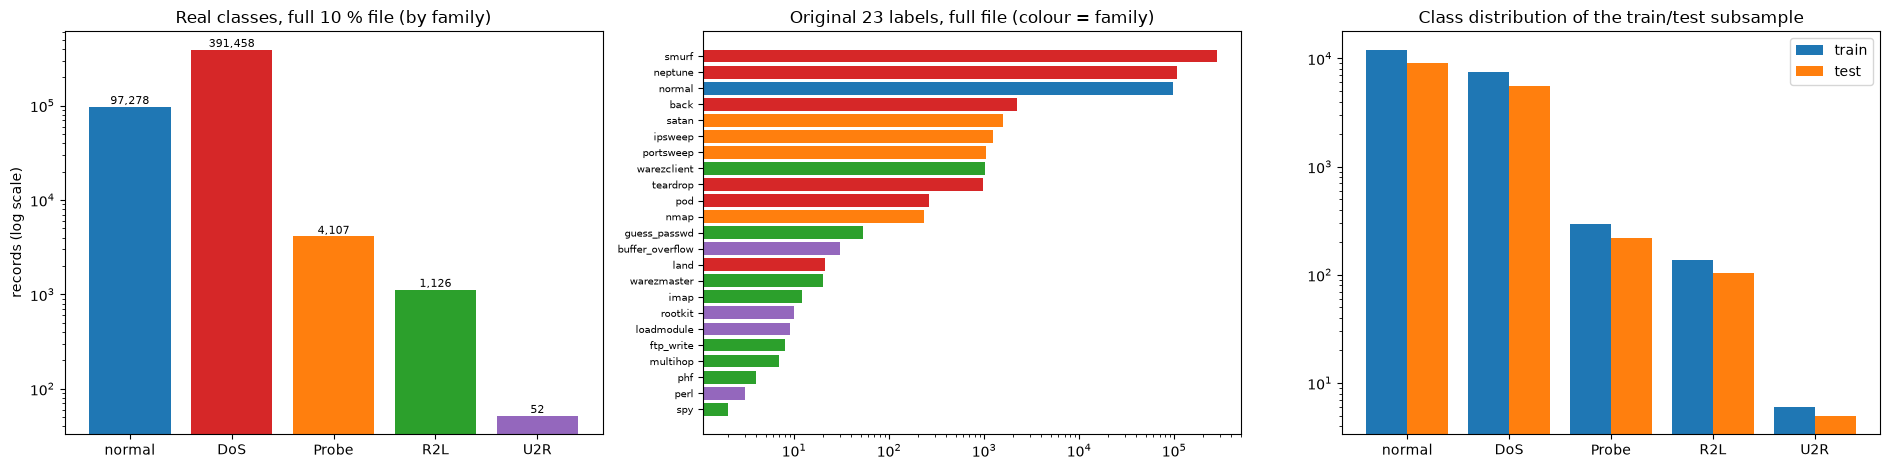

In [6]:
print("Full KDD99 10 % file:", raw.shape[0], "records,", len(ALL_FEATURES), "features + label")
print("All 41 feature names:\n ", ", ".join(ALL_FEATURES))
n_oh = sum(1 for f in S["feat_names"] if f.startswith(tuple(c + "_" for c in CAT_COLS)))
print(f"Encoded input width used by the networks: {N_IN} = {n_oh} one-hot columns ({chr(44).join(CAT_COLS)}) + {N_IN - n_oh} numeric columns")
lab = raw.groupby(["label", "family"]).size().rename("records (full file)").reset_index()
lab["records (pool)"] = lab["label"].map(POOL["label"].value_counts()).fillna(0).astype(int)
lab["train"] = lab["label"].map(S["tr"]["label"].value_counts()).fillna(0).astype(int)
lab["test"] = lab["label"].map(S["te"]["label"].value_counts()).fillna(0).astype(int)
lab = lab.sort_values("records (full file)", ascending=False)
print(f"\nOriginal label values ({lab.shape[0]} distinct) and counts:")
display(lab.set_index("label"))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
fc = raw.family.value_counts().reindex(FAMILY_ORDER)
axes[0].bar(fc.index, fc.values, color=[FAMILY_COLOR[f] for f in fc.index]); axes[0].set_yscale("log")
axes[0].set_title("Real classes, full 10 % file (by family)"); axes[0].set_ylabel("records (log scale)")
for i, v in enumerate(fc.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
lp = lab.iloc[::-1]
axes[1].barh(lp.label, lp["records (full file)"], color=[FAMILY_COLOR[f] for f in lp.family]); axes[1].set_xscale("log")
axes[1].set_title("Original 23 labels, full file (colour = family)"); axes[1].tick_params(axis="y", labelsize=7)
w = 0.4; xs = np.arange(len(FAMILY_ORDER))
axes[2].bar(xs - w / 2, S["tr"]["family"].value_counts().reindex(FAMILY_ORDER).fillna(0).values, w, label="train")
axes[2].bar(xs + w / 2, S["te"]["family"].value_counts().reindex(FAMILY_ORDER).fillna(0).values, w, label="test")
axes[2].set_xticks(xs); axes[2].set_xticklabels(FAMILY_ORDER); axes[2].set_yscale("log"); axes[2].legend(); axes[2].set_title("Class distribution of the train/test subsample")
plt.tight_layout(); plt.show()


PCA explained variance of the first 2 / 8 components: 39.5 % / 69.5 %


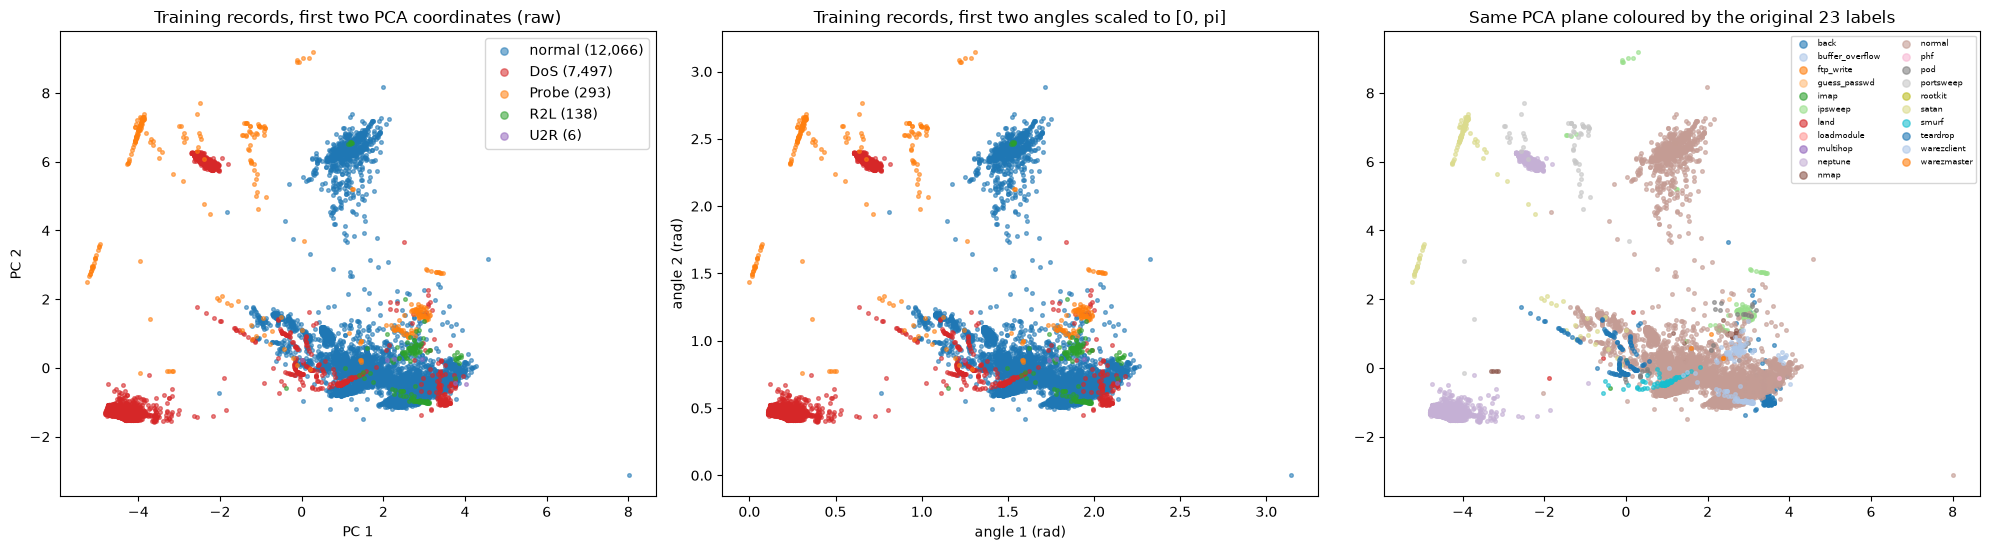

In [7]:
# 2-D scatter of REAL training records coloured by ground-truth label.
# (a) raw PCA coordinates (PCA fitted on the training split only); (b) the first two angles after scaling to [0, pi]
# (the quantum layer encodes its inputs as RY angles, so this is the geometry of an angle encoding of the PCA coordinates).
pca = PCA(n_components=N_QUBITS, random_state=SEED).fit(Xtr)
Ptr = pca.transform(Xtr)
angle_sc = MinMaxScaler((0, np.pi)).fit(Ptr)
Atr = angle_sc.transform(Ptr)
print("PCA explained variance of the first 2 / 8 components: %.1f %% / %.1f %%" % (100 * pca.explained_variance_ratio_[:2].sum(), 100 * pca.explained_variance_ratio_.sum()))
fam_tr = S["tr"]["family"].values
fig, axes = plt.subplots(1, 3, figsize=(20, 5.6))
for fam in FAMILY_ORDER:
    m = fam_tr == fam
    axes[0].scatter(Ptr[m, 0], Ptr[m, 1], s=7, alpha=0.55, c=FAMILY_COLOR[fam], label=f"{fam} ({m.sum():,})")
    axes[1].scatter(Atr[m, 0], Atr[m, 1], s=7, alpha=0.55, c=FAMILY_COLOR[fam], label=fam)
axes[0].set_title("Training records, first two PCA coordinates (raw)"); axes[0].set_xlabel("PC 1"); axes[0].set_ylabel("PC 2"); axes[0].legend(markerscale=2)
axes[1].set_title("Training records, first two angles scaled to [0, pi]"); axes[1].set_xlabel("angle 1 (rad)"); axes[1].set_ylabel("angle 2 (rad)")
cmap = plt.get_cmap("tab20")
for i, l in enumerate(LABELS):
    m = S["tr"]["label"].values == l
    if m.any(): axes[2].scatter(Ptr[m, 0], Ptr[m, 1], s=7, alpha=0.6, color=cmap(i % 20), label=l)
axes[2].set_title("Same PCA plane coloured by the original 23 labels"); axes[2].legend(fontsize=6, ncol=2, markerscale=2)
plt.tight_layout(); plt.show()


## Quantum Circuit Architecture

This is the quantum layer exactly as the paper defines it (equations 1 to 6 and Fig. 2), written as a PennyLane QNode for **one record** `x` (8 numbers) and one weight row `w` (8 numbers):

1. `H` on each of the 8 qubits (uniform superposition, eq. 1);
2. `RY(x_i * pi)` on qubit `i` (data encoding `U_x`, eq. 3);
3. controlled-`RY(w_i * 2 pi)` on the qubit pairs `(0,1), (2,3), (4,5), (6,7)`, once with the first qubit as control and once with the second (entangling block `U_w`, eq. 4 and Fig. 2);
4. measure the expectation of `Z (x) Z (x) ... (x) Z` on all 8 qubits (eq. 5), a single number in [-1, 1]. The classical map `f` multiplies it by fixed factors to produce 8 outputs.

**Assumptions where the paper is silent.** Fig. 2 draws only the Hadamards and the controlled gates (all parameters set to 20 for illustration) without the `RY` encoding gates; we place the `RY` encoding after the Hadamards (eq. 3 and 6, `|phi> = U_w U_x |psi>`). The pairing and the use of both control directions follow Fig. 2 and eq. 4. The *ablation* variant measures every qubit separately (`Z_i`, 8 numbers) instead of the single product `Z^(x)8`.

The training loop does not call this QNode for every batch (PennyLane needs more than a second per batch of 64 on a laptop CPU). It uses an **exact PyTorch statevector simulator** of the same gate list (full 256-amplitude state, with the two controlled gates of each pair fused into one 4x4 block, about 10 ms per batch), and the cell below asserts that the simulator equals the real QNode (and a Qiskit circuit) to numerical precision.

Matplotlib is building the font cache; this may take a moment.


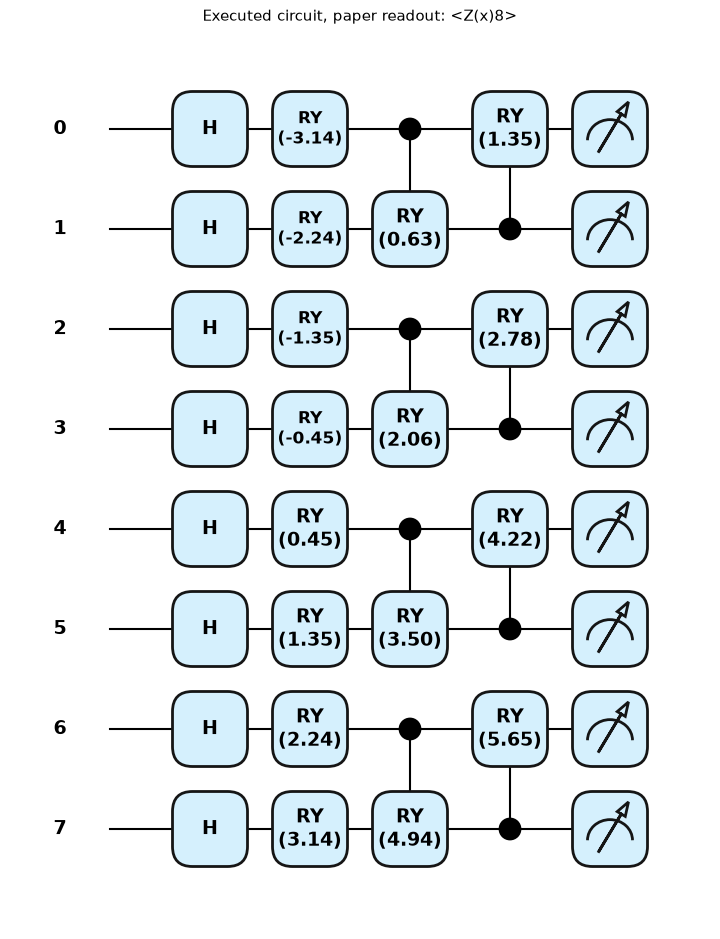

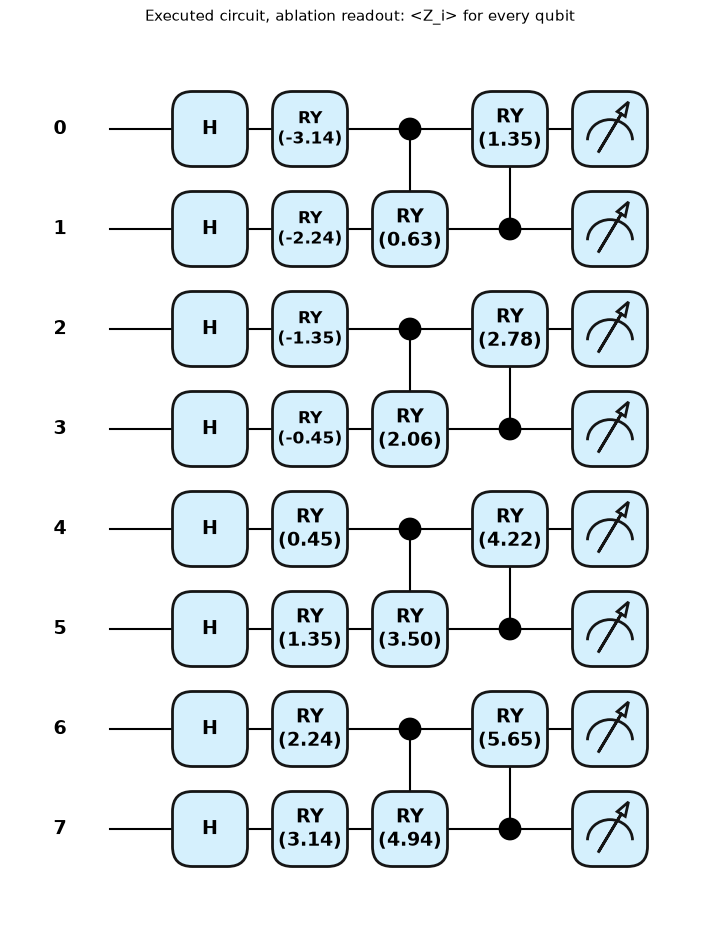

qubits: 8 | circuit depth: 4 | gates: {'Hadamard': 8, 'RY': 8, 'CRY': 8}
trainable parameters per sample inside the circuit: 8 weights (data angles are inputs, not trainable)
trainable parameters of the paper's quantum layer W (k x n): 64 x 8 = 512


In [8]:
n = N_QUBITS
PAIRS = [(2 * p, 2 * p + 1) for p in range(n // 2)]              # CHOICE (read from Fig. 2): neighbouring pairs
dev = qml.device("default.qubit", wires=n)

def _circuit(x, w):
    for i in range(n): qml.Hadamard(wires=i)                      # uniform superposition |psi>
    for i in range(n): qml.RY(x[i] * np.pi, wires=i)              # U_x: data encoding
    for (a, b) in PAIRS:                                          # U_w: entangling controlled-RY in both directions
        qml.CRY(w[a] * 2 * np.pi, wires=[a, b])
        qml.CRY(w[b] * 2 * np.pi, wires=[b, a])

@qml.qnode(dev)
def qnode_scalar(x, w):                                           # paper: expectation of Z (x) ... (x) Z
    _circuit(x, w)
    return qml.expval(qml.prod(*[qml.PauliZ(i) for i in range(n)]))

@qml.qnode(dev)
def qnode_perqubit(x, w):                                         # ablation: <Z_i> on every qubit
    _circuit(x, w)
    return [qml.expval(qml.PauliZ(i)) for i in range(n)]

x0 = np.linspace(-1.0, 1.0, n); w0 = np.linspace(0.1, 0.9, n)
fig, ax = qml.draw_mpl(qnode_scalar, decimals=2, style="pennylane")(x0, w0)
ax.set_title("Executed circuit, paper readout: <Z(x)8>", fontsize=11); plt.show()
fig, ax = qml.draw_mpl(qnode_perqubit, decimals=2, style="pennylane")(x0, w0)
ax.set_title("Executed circuit, ablation readout: <Z_i> for every qubit", fontsize=11); plt.show()

specs = qml.specs(qnode_scalar)(x0, w0)
res = specs["resources"] if isinstance(specs, dict) else specs.resources
print("qubits:", n, "| circuit depth:", res.depth, "| gates:", dict(res.gate_types))
print("trainable parameters per sample inside the circuit: 8 weights (data angles are inputs, not trainable)")
print("trainable parameters of the paper's quantum layer W (k x n):", BATCH_SIZE, "x", n, "=", BATCH_SIZE * n)


In [9]:
# Exact batched statevector simulator used for training (all gates are real: H, RY, CRY, so the state is real-valued).
# Same gate list as the QNode above, executed with gate fusion: H^(x)8 |0> followed by RY(x_i pi) is a product state of
# 8 single-qubit vectors, and the two controlled-RY gates of a pair (a,b) are multiplied into one 4x4 block per pair.
PARITY = torch.tensor([(-1.0) ** bin(i).count("1") for i in range(2 ** n)], dtype=torch.float64)                    # eigenvalues of Z^(x)n
ZSIGN = torch.tensor([[1.0 - 2.0 * ((i >> (n - 1 - q)) & 1) for q in range(n)] for i in range(2 ** n)], dtype=torch.float64)   # <Z_q> signs (qubit 0 = most significant)
# 4x4 templates in the basis |q_a q_b> (index 2 q_a + q_b): CRY(a->b) acts on indices {2,3}, CRY(b->a) on indices {1,3}
_E0 = torch.zeros(2, 4, 4, dtype=torch.float64); _EC = torch.zeros_like(_E0); _ES = torch.zeros_like(_E0)
for d, (idle, (lo, hi)) in enumerate([((0, 1), (2, 3)), ((0, 2), (1, 3))]):
    for k in idle: _E0[d, k, k] = 1.0
    for k in (lo, hi): _EC[d, k, k] = 1.0
    _ES[d, lo, hi], _ES[d, hi, lo] = -1.0, 1.0

def simulate_state(x, w):
    """x, w: (B, n) float64 -> real statevector (B, 2^n); equals the QNode circuit |phi> = U_w U_x H^(x)n |0>."""
    B = x.shape[0]
    c1, s1 = torch.cos(x * math.pi / 2), torch.sin(x * math.pi / 2)
    v = torch.stack([(c1 - s1) / math.sqrt(2.0), (s1 + c1) / math.sqrt(2.0)], -1)                      # RY(x_i pi) H |0>, shape (B, n, 2)
    pair = (v[:, 0::2, :, None] * v[:, 1::2, None, :]).reshape(B, n // 2, 4)                            # product state of each pair
    c, s = torch.cos(math.pi * w).reshape(B, n // 2, 2), torch.sin(math.pi * w).reshape(B, n // 2, 2)  # cos/sin of (w 2pi / 2)
    M = _E0 + c[..., None, None] * _EC + s[..., None, None] * _ES                                      # (B, pairs, 2 directions, 4, 4)
    U = M[:, :, 1] @ M[:, :, 0]                                                                        # CRY(a->b) first, then CRY(b->a)
    pair = torch.einsum("bpij,bpj->bpi", U, pair)
    psi = pair[:, 0]
    for p in range(1, n // 2): psi = (psi[:, :, None] * pair[:, p, None, :]).reshape(B, -1)             # tensor product of the pairs
    return psi

def q_expect(x, w, readout="scalar"):
    prob = simulate_state(x.double(), w.double()) ** 2
    return (prob @ PARITY)[:, None] if readout == "scalar" else prob @ ZSIGN

# ... checked against (1) the PennyLane QNode, (2) a Qiskit circuit, (3) an independent product-of-pairs numpy formula
rs = np.random.default_rng(0)
Xc, Wc = rs.normal(size=(6, n)), rs.uniform(size=(6, n))
sim_s = q_expect(torch.tensor(Xc), torch.tensor(Wc)).numpy()[:, 0]
sim_q = q_expect(torch.tensor(Xc), torch.tensor(Wc), "qubit").numpy()
pl_s = np.array([float(qnode_scalar(Xc[k], Wc[k])) for k in range(6)])
pl_q = np.array([[float(v) for v in qnode_perqubit(Xc[k], Wc[k])] for k in range(6)])
assert np.allclose(sim_s, pl_s, atol=1e-9) and np.allclose(sim_q, pl_q, atol=1e-9), "simulator != PennyLane QNode"

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
def qiskit_circuit(x, w):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for i in range(n): qc.ry(float(x[i]) * np.pi, i)
    for (a, b) in PAIRS:
        qc.cry(float(w[a]) * 2 * np.pi, a, b); qc.cry(float(w[b]) * 2 * np.pi, b, a)
    return qc
zall = SparsePauliOp("Z" * n)
qk_s = np.array([Statevector(qiskit_circuit(Xc[k], Wc[k])).expectation_value(zall).real for k in range(6)])
assert np.allclose(sim_s, qk_s, atol=1e-9), "simulator != Qiskit circuit"
print("Qiskit circuit depth:", qiskit_circuit(Xc[0], Wc[0]).decompose().depth(), "| ops:", dict(qiskit_circuit(Xc[0], Wc[0]).count_ops()))

def closed_form(x, w):                           # <Z(x)8> factorises over the four independent qubit pairs
    out = 1.0
    for (a, b) in PAIRS:
        st = np.zeros(4); st[0] = 1.0
        h = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
        ry = lambda t: np.array([[np.cos(t / 2), -np.sin(t / 2)], [np.sin(t / 2), np.cos(t / 2)]])
        st = np.kron(h, h) @ st
        st = np.kron(ry(x[a] * np.pi), ry(x[b] * np.pi)) @ st
        cry_ab = np.block([[np.eye(2), np.zeros((2, 2))], [np.zeros((2, 2)), ry(w[a] * 2 * np.pi)]])           # control a, target b
        P0, P1 = np.diag([1, 0]), np.diag([0, 1])
        cry_ba = np.kron(np.eye(2), P0) + np.kron(ry(w[b] * 2 * np.pi), P1)                                     # control b, target a
        st = cry_ba @ (cry_ab @ st)
        out *= st @ np.kron(np.diag([1, -1]), np.diag([1, -1])) @ st
    return out
cf = np.array([closed_form(Xc[k], Wc[k]) for k in range(6)])
assert np.allclose(sim_s, cf, atol=1e-9), "simulator != product-of-pairs closed form"
print("Equivalence asserted: PyTorch simulator == PennyLane QNode == Qiskit circuit == 4 independent 2-qubit blocks (max abs diff %.1e)" % max(abs(sim_s - pl_s).max(), abs(sim_s - qk_s).max(), abs(sim_s - cf).max()))


Qiskit circuit depth: 10 | ops: {'h': 8, 'ry': 8, 'cry': 8}
Equivalence asserted: PyTorch simulator == PennyLane QNode == Qiskit circuit == 4 independent 2-qubit blocks (max abs diff 7.2e-16)


## 3. The hybrid networks

`QLayer` is the paper's layer. Its input is the previous dense layer's 8 numbers; the **paper variant** keeps a trainable weight matrix `W` of shape `64 x 8` and uses row `j` for the `j`-th record of each batch (this reproduces the 512 parameters per quantum layer behind Table III); the **shared variant** keeps a single `1 x 8` row for all records. The single expectation value is expanded to 8 numbers by fixed scaling factors (`# CHOICE:`). Dense layers have no activation, exactly as in the paper's Algorithm 2; the quantum layer is the only non-linearity.

Controls on identical inputs: the same ARCH1 with `tanh` instead of the quantum layer, the same with a classical *rank-one* bottleneck (`tanh(mean)` times the same fixed factors, so it has the same information bottleneck as the quantum layer), and the same with no activation at all.

In [10]:
SCALES = torch.linspace(0.5, 2.0, n)               # CHOICE: fixed (non-trainable) scaling factors of f

class QLayer(nn.Module):
    def __init__(self, shared=False, readout="scalar"):
        super().__init__()
        self.shared, self.readout = shared, readout
        self.W = nn.Parameter(torch.rand(1 if shared else BATCH_SIZE, n))      # CHOICE: W ~ U(0,1)
        self.register_buffer("scales", SCALES.clone())
    def forward(self, h):
        B = h.shape[0]
        w = self.W.expand(B, n) if self.shared else self.W[:B]                  # paper: row j of W for the j-th record of the batch
        z = q_expect(h, w, self.readout).float()
        return z * self.scales if self.readout == "scalar" else z

class RankOne(nn.Module):                           # classical control with the same 1-number bottleneck
    def __init__(self):
        super().__init__(); self.register_buffer("scales", SCALES.clone())
    def forward(self, h): return torch.tanh(h.mean(1, keepdim=True)) * self.scales

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def build(arch, n_in=None):
    n_in = N_IN if n_in is None else n_in
    L = nn.Linear
    if arch == "QA-ARCH1 (paper)":          return nn.Sequential(L(n_in, 8), QLayer(), L(8, 10), L(10, N_CLASSES))
    if arch == "QA-ARCH1 (shared W)":       return nn.Sequential(L(n_in, 8), QLayer(shared=True), L(8, 10), L(10, N_CLASSES))
    if arch == "QA-ARCH1 (shared W, Z_i readout)": return nn.Sequential(L(n_in, 8), QLayer(shared=True, readout="qubit"), L(8, 10), L(10, N_CLASSES))
    if arch == "Classical ARCH1 (tanh)":    return nn.Sequential(L(n_in, 8), nn.Tanh(), L(8, 10), L(10, N_CLASSES))
    if arch == "Classical ARCH1 (rank-1 tanh)": return nn.Sequential(L(n_in, 8), RankOne(), L(8, 10), L(10, N_CLASSES))
    if arch == "Linear ARCH1 (no activation)":  return nn.Sequential(L(n_in, 8), L(8, 10), L(10, N_CLASSES))
    if arch == "QA-ARCH2 (paper)":          return nn.Sequential(L(n_in, 10), L(10, 8), QLayer(), QLayer(), L(8, N_CLASSES))
    if arch.startswith("SWEEP-"):
        k = int(arch.split("-")[1]); return nn.Sequential(L(n_in, 8), *[QLayer() for _ in range(k)], L(8, 10), L(10, N_CLASSES))
    raise KeyError(arch)

# Table III check: with the paper's 120 input features the parameter counts must be 1823 (ARCH1) and 2529 (ARCH2)
for arch, paper in [("QA-ARCH1 (paper)", 1823), ("QA-ARCH2 (paper)", 2529)]:
    m120 = build(arch, n_in=120)
    print(f"{arch}: trainable parameters with 120 inputs = {n_params(m120)} (paper Table III: {paper}) -> {'MATCH' if n_params(m120) == paper else 'DIFFERENT'};  with our {N_IN} inputs = {n_params(build(arch))}")
    assert n_params(m120) == paper


QA-ARCH1 (paper): trainable parameters with 120 inputs = 1823 (paper Table III: 1823) -> MATCH;  with our 112 inputs = 1759
QA-ARCH2 (paper): trainable parameters with 120 inputs = 2529 (paper Table III: 2529) -> MATCH;  with our 112 inputs = 2449


In [11]:
def make_opt(model):
    opt = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda step: 1.0 / (1.0 + LR_DECAY * step))     # legacy-Keras decay
    return opt, sched

@torch.no_grad()
def predict(model, X, return_hidden=False):
    model.eval()
    X = torch.as_tensor(X); out = []
    for i in range(0, len(X), BATCH_SIZE):
        out.append(model(X[i:i + BATCH_SIZE]))                                  # test batches also have size 64 (paper W has 64 rows)
    return torch.cat(out).argmax(1).numpy()

def train(arch, seed, epochs, Xa, ya, Xb=None, yb=None, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed)
    model = build(arch, Xa.shape[1]); opt, sched = make_opt(model)   # input width can differ slightly between seeds (train-only one-hot vocabulary)
    Xt, yt = torch.as_tensor(Xa), torch.as_tensor(ya, dtype=torch.long)
    g = torch.Generator().manual_seed(seed)
    hist = []; t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xt), generator=g)
        tot, cor, cnt = 0.0, 0, 0
        for i in range(0, len(Xt) - BATCH_SIZE + 1, BATCH_SIZE):                  # drop the last partial batch (W has exactly 64 rows)
            idx = perm[i:i + BATCH_SIZE]
            logits = model(Xt[idx]); loss = F.cross_entropy(logits, yt[idx])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tot += loss.item() * len(idx); cor += (logits.argmax(1) == yt[idx]).sum().item(); cnt += len(idx)
        rec = dict(epoch=ep + 1, loss=tot / cnt, train_acc=cor / cnt)             # Keras-style running training accuracy
        if Xb is not None and (ep == epochs - 1 or verbose): rec["test_acc"] = accuracy_score(yb, predict(model, Xb))
        hist.append(rec)
        if verbose: print(f"  {arch} | seed {seed} | epoch {ep + 1}/{epochs} | loss {rec['loss']:.4f} | train acc {rec['train_acc']:.4f}" + (f" | test acc {rec['test_acc']:.4f}" if 'test_acc' in rec else "") + f" | {time.time() - t0:.0f}s")
    return model, pd.DataFrame(hist), time.time() - t0

FAM_OF = np.array([FAMILY[l] for l in LABELS]); NORMAL_ID = LABEL_ID["normal"]
def metrics(y_true, y_pred):
    bt, bp = (y_true != NORMAL_ID).astype(int), (y_pred != NORMAL_ID).astype(int)            # attack = positive class
    return dict(acc=accuracy_score(y_true, y_pred), macro_f1=f1_score(y_true, y_pred, average="macro", zero_division=0),
                weighted_f1=f1_score(y_true, y_pred, average="weighted", zero_division=0),
                bin_acc=accuracy_score(bt, bp), bin_precision=precision_score(bt, bp, zero_division=0),
                bin_recall=recall_score(bt, bp, zero_division=0), bin_f1=f1_score(bt, bp, zero_division=0))


## 4. Train ARCH1 with the quantum activation (learning curve, the analogue of the paper's Fig. 5)

The running training accuracy and loss per epoch are what Keras prints and what Fig. 5 plots. The test accuracy is computed on the held-out records.

  QA-ARCH1 (paper) | seed 42 | epoch 1/15 | loss 0.4411 | train acc 0.9157 | test acc 0.9520 | 9s


  QA-ARCH1 (paper) | seed 42 | epoch 2/15 | loss 0.2217 | train acc 0.9505 | test acc 0.9521 | 18s


  QA-ARCH1 (paper) | seed 42 | epoch 3/15 | loss 0.2235 | train acc 0.9517 | test acc 0.9559 | 25s


  QA-ARCH1 (paper) | seed 42 | epoch 4/15 | loss 0.1986 | train acc 0.9550 | test acc 0.9561 | 34s


  QA-ARCH1 (paper) | seed 42 | epoch 5/15 | loss 0.1753 | train acc 0.9568 | test acc 0.9578 | 44s


...

  QA-ARCH1 (paper) | seed 42 | epoch 11/15 | loss 0.1372 | train acc 0.9606 | test acc 0.9597 | 89s


  QA-ARCH1 (paper) | seed 42 | epoch 12/15 | loss 0.1337 | train acc 0.9604 | test acc 0.9614 | 97s


  QA-ARCH1 (paper) | seed 42 | epoch 13/15 | loss 0.1297 | train acc 0.9609 | test acc 0.9619 | 104s


  QA-ARCH1 (paper) | seed 42 | epoch 14/15 | loss 0.1237 | train acc 0.9618 | test acc 0.9628 | 111s


  QA-ARCH1 (paper) | seed 42 | epoch 15/15 | loss 0.1243 | train acc 0.9614 | test acc 0.9614 | 118s


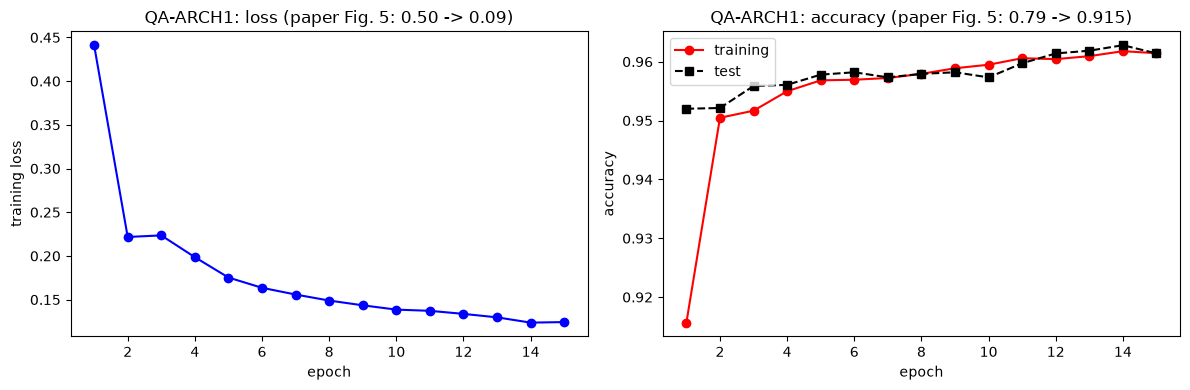

In [12]:
t_all = time.time()
model_q1, hist_q1, sec_q1 = train("QA-ARCH1 (paper)", SEED, EPOCHS, Xtr, ytr, Xte, yte)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_q1.epoch, hist_q1.loss, "b-o"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training loss"); ax[0].set_title("QA-ARCH1: loss (paper Fig. 5: 0.50 -> 0.09)")
ax[1].plot(hist_q1.epoch, hist_q1.train_acc, "r-o", label="training"); ax[1].plot(hist_q1.epoch, hist_q1.test_acc, "k--s", label="test")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].set_title("QA-ARCH1: accuracy (paper Fig. 5: 0.79 -> 0.915)"); ax[1].legend()
plt.tight_layout(); plt.show()


## 5. All models on identical inputs, several seeds

Every neural model sees the same standardised input matrix and the same training records for a given seed. Random Forest and an RBF SVC are trained on the same matrix (the SVC on at most `SVC_MAX_TRAIN` records). Metrics are the paper's accuracy plus macro F1, and the binary attack-versus-normal view with attack as the positive class.

In [13]:
ARCHS = ["QA-ARCH1 (paper)", "QA-ARCH1 (shared W)", "QA-ARCH1 (shared W, Z_i readout)", "QA-ARCH2 (paper)",
         "Classical ARCH1 (tanh)", "Classical ARCH1 (rank-1 tanh)", "Linear ARCH1 (no activation)"]
rows, preds, hists, models = [], {}, {}, {}
for sd in SEEDS:
    Ssd = S if sd == SEED else make_split(sd)
    Xa, ya, Xb, yb = Ssd["Xtr"], Ssd["ytr"], Ssd["Xte"], Ssd["yte"]
    for arch in ARCHS:
        if sd == SEED and arch == "QA-ARCH1 (paper)":
            model, hist, sec = model_q1, hist_q1, sec_q1                               # already trained in Section 4
        else:
            model, hist, sec = train(arch, sd, EPOCHS, Xa, ya, Xb, yb, verbose=False)
        yp = predict(model, Xb)
        rows.append(dict(model=arch, seed=sd, params=n_params(model), seconds=sec, final_train_acc=hist.train_acc.iloc[-1], first_train_acc=hist.train_acc.iloc[0], **metrics(yb, yp)))
        if sd == SEED: preds[arch] = yp; hists[arch] = hist; models[arch] = model
        print(f"seed {sd} | {arch:36s} | test acc {rows[-1]['acc']:.4f} | macro-F1 {rows[-1]['macro_f1']:.3f} | train acc {rows[-1]['final_train_acc']:.4f} | {sec:.0f}s")
    for name, clf in [("Random Forest", RandomForestClassifier(n_estimators=200, random_state=sd, n_jobs=2)),
                      ("SVC (rbf)", SVC(kernel="rbf", C=1.0, gamma="scale"))]:
        t0 = time.time(); k = SVC_MAX_TRAIN if name.startswith("SVC") else len(Xa)
        clf.fit(Xa[:k], ya[:k]); yp = clf.predict(Xb); sec = time.time() - t0
        rows.append(dict(model=name, seed=sd, params=np.nan, seconds=sec, final_train_acc=np.nan, first_train_acc=np.nan, **metrics(yb, yp)))
        if sd == SEED: preds[name] = yp
        print(f"seed {sd} | {name:36s} | test acc {rows[-1]['acc']:.4f} | macro-F1 {rows[-1]['macro_f1']:.3f} | {sec:.0f}s")
RES = pd.DataFrame(rows)
print(f"total wall-clock of this section: {(time.time() - t_all) / 60:.1f} min")


seed 42 | QA-ARCH1 (paper)                     | test acc 0.9614 | macro-F1 0.145 | train acc 0.9614 | 118s


seed 42 | QA-ARCH1 (shared W)                  | test acc 0.9711 | macro-F1 0.181 | train acc 0.9697 | 110s


seed 42 | QA-ARCH1 (shared W, Z_i readout)     | test acc 0.9947 | macro-F1 0.556 | train acc 0.9966 | 99s


seed 42 | QA-ARCH2 (paper)                     | test acc 0.7401 | macro-F1 0.071 | train acc 0.7331 | 161s


seed 42 | Classical ARCH1 (tanh)               | test acc 0.9965 | macro-F1 0.688 | train acc 0.9981 | 26s


...

seed 44 | Classical ARCH1 (tanh)               | test acc 0.9959 | macro-F1 0.641 | train acc 0.9977 | 45s


seed 44 | Classical ARCH1 (rank-1 tanh)        | test acc 0.9664 | macro-F1 0.173 | train acc 0.9679 | 46s


seed 44 | Linear ARCH1 (no activation)         | test acc 0.9956 | macro-F1 0.628 | train acc 0.9974 | 47s


seed 44 | Random Forest                        | test acc 0.9982 | macro-F1 0.669 | 40s


seed 44 | SVC (rbf)                            | test acc 0.9958 | macro-F1 0.609 | 22s
total wall-clock of this section: 37.0 min


In [14]:
summ = RES.groupby("model", sort=False).agg(params=("params", "first"), acc_mean=("acc", "mean"), acc_std=("acc", "std"), macro_f1=("macro_f1", "mean"),
                                           bin_acc=("bin_acc", "mean"), bin_f1=("bin_f1", "mean"), bin_recall=("bin_recall", "mean"),
                                           train_acc_last=("final_train_acc", "mean"), seconds=("seconds", "mean")).round(4)
print(f"Test results (mean over seeds {SEEDS}; std is NaN with one seed):")
display(summ)


Test results (mean over seeds [42, 43, 44]; std is NaN with one seed):


,params,acc_mean,acc_std,macro_f1,bin_acc,bin_f1,bin_recall,train_acc_last,seconds
model,,,,,,,,,
QA-ARCH1 (paper),1759.0,0.9588,0.0031,0.1225,0.9673,0.9572,0.9221,0.9587,117.0522
QA-ARCH1 (shared W),1255.0,0.9680,0.0026,0.1720,0.9822,0.9771,0.9599,0.9673,129.5579
"QA-ARCH1 (shared W, Z_i readout)",1255.0,0.9954,0.0006,0.5444,0.9966,0.9957,0.9955,0.9963,117.4461
QA-ARCH2 (paper),2449.0,0.8434,0.0898,0.0841,0.8651,0.7981,0.7854,0.8389,202.9341
Classical ARCH1 (tanh),1247.0,0.9965,0.0006,0.6825,0.9972,0.9964,0.9968,0.9982,37.2120
Classical ARCH1 (rank-1 tanh),1247.0,0.9683,0.0017,0.1794,0.9863,0.9824,0.9695,0.9678,40.5066
Linear ARCH1 (no activation),1247.0,0.9962,0.0006,0.6717,0.9968,0.9960,0.9971,0.9980,36.1911
Random Forest,NaN,0.9984,0.0002,0.7050,0.9986,0.9983,0.9969,NaN,25.0101
SVC (rbf),NaN,0.9960,0.0006,0.6003,0.9964,0.9954,0.9930,NaN,16.4257


### Confusion matrices (attack = positive class) and per-family results

The paper reports only overall accuracy. A 23-class accuracy near the share of the two dominant classes can hide completely missed attack families, so we also look at the binary attack-versus-normal confusion matrix and the recall per attack family for the quantum network and its classical controls.

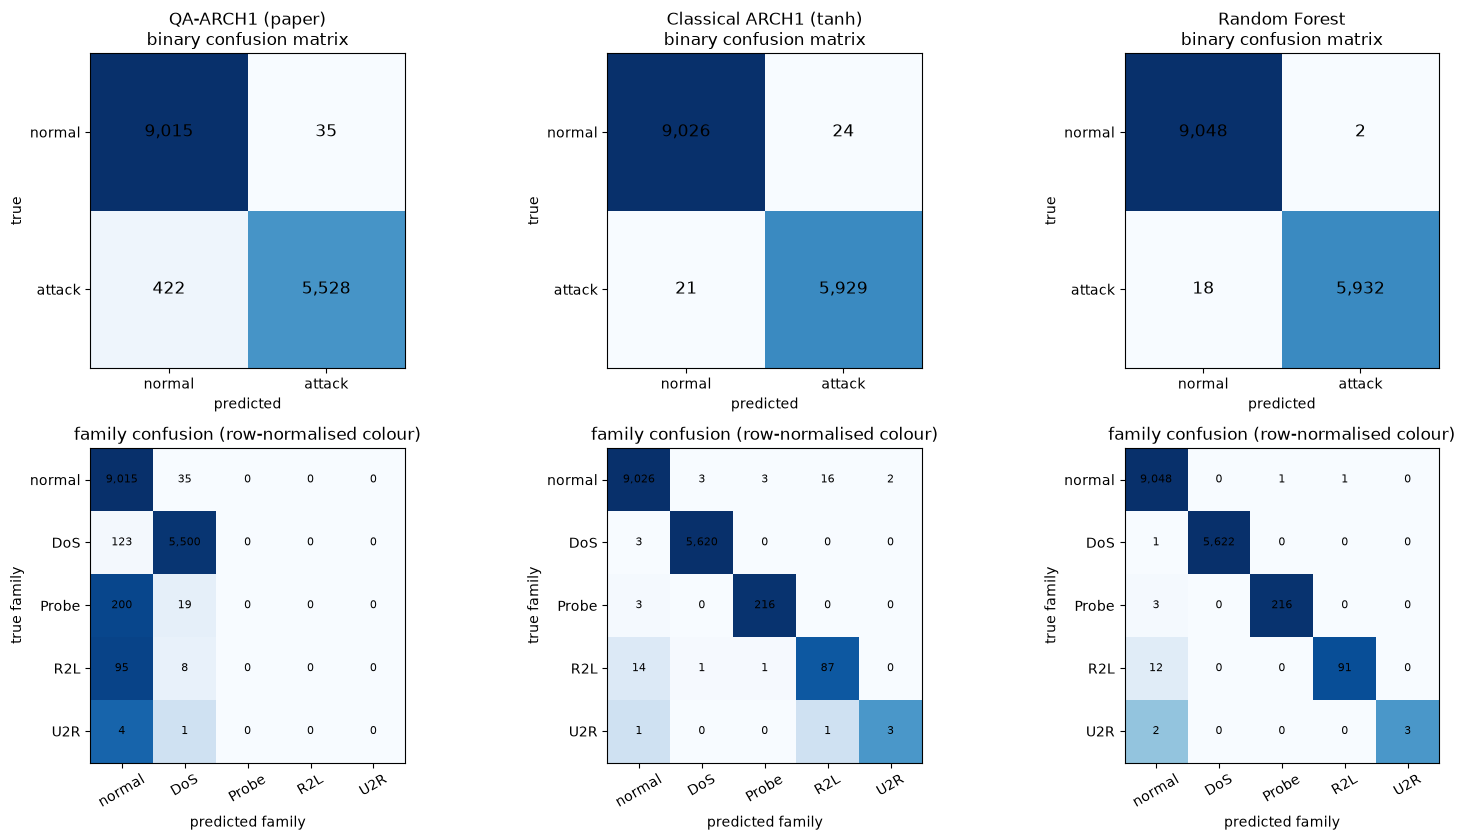

Recall per family on the test subsample (seed 42):


,QA-ARCH1 (paper),Classical ARCH1 (tanh),Random Forest,SVC (rbf)
normal,0.996,0.997,1.000,0.998
DoS,0.978,0.999,1.000,0.998
Probe,0.000,0.986,0.986,0.954
R2L,0.000,0.845,0.883,0.825
U2R,0.000,0.600,0.600,0.000


test records per family: {'normal': 9050, 'DoS': 5623, 'Probe': 219, 'R2L': 103, 'U2R': 5}


In [15]:
show = ["QA-ARCH1 (paper)", "Classical ARCH1 (tanh)", "Random Forest"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for j, name in enumerate(show):
    yp = preds[name]
    cm = confusion_matrix((yte != NORMAL_ID).astype(int), (yp != NORMAL_ID).astype(int), labels=[0, 1])
    axes[0, j].imshow(cm, cmap="Blues")
    for a in range(2):
        for b in range(2): axes[0, j].text(b, a, f"{cm[a, b]:,}", ha="center", va="center", color="black", fontsize=12)
    axes[0, j].set_xticks([0, 1]); axes[0, j].set_xticklabels(["normal", "attack"]); axes[0, j].set_yticks([0, 1]); axes[0, j].set_yticklabels(["normal", "attack"])
    axes[0, j].set_xlabel("predicted"); axes[0, j].set_ylabel("true"); axes[0, j].set_title(f"{name}\nbinary confusion matrix")
    fam_true = np.array([FAMILY[LABELS[k]] for k in yte]); fam_pred = np.array([FAMILY[LABELS[k]] for k in yp])
    cmf = confusion_matrix(fam_true, fam_pred, labels=FAMILY_ORDER)
    axes[1, j].imshow(cmf / np.maximum(cmf.sum(1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
    for a in range(5):
        for b in range(5): axes[1, j].text(b, a, f"{cmf[a, b]:,}", ha="center", va="center", fontsize=8)
    axes[1, j].set_xticks(range(5)); axes[1, j].set_xticklabels(FAMILY_ORDER, rotation=30); axes[1, j].set_yticks(range(5)); axes[1, j].set_yticklabels(FAMILY_ORDER)
    axes[1, j].set_xlabel("predicted family"); axes[1, j].set_ylabel("true family"); axes[1, j].set_title("family confusion (row-normalised colour)")
plt.tight_layout(); plt.show()
fam_true = np.array([FAMILY[LABELS[k]] for k in yte])
rec = {name: {f: float(np.mean(np.array([FAMILY[LABELS[k]] for k in preds[name]])[fam_true == f] == f)) if (fam_true == f).any() else np.nan for f in FAMILY_ORDER} for name in ARCHS[:1] + ARCHS[4:5] + ["Random Forest", "SVC (rbf)"]}
print("Recall per family on the test subsample (seed %d):" % SEED); display(pd.DataFrame(rec).round(3))
print("test records per family:", {f: int((fam_true == f).sum()) for f in FAMILY_ORDER})


### Where the quantum layer sees the data

After training, the 8 numbers that enter the quantum layer are the rotation angles `x_i * pi` (mod 2 pi) of the 8 qubits. Below, the real test records are plotted at their first two qubit angles, coloured by ground-truth family. The right panel shows what the circuit does with them: the single expectation value `<Z^(x)8>` that is the *only* information passed on to the next layer.

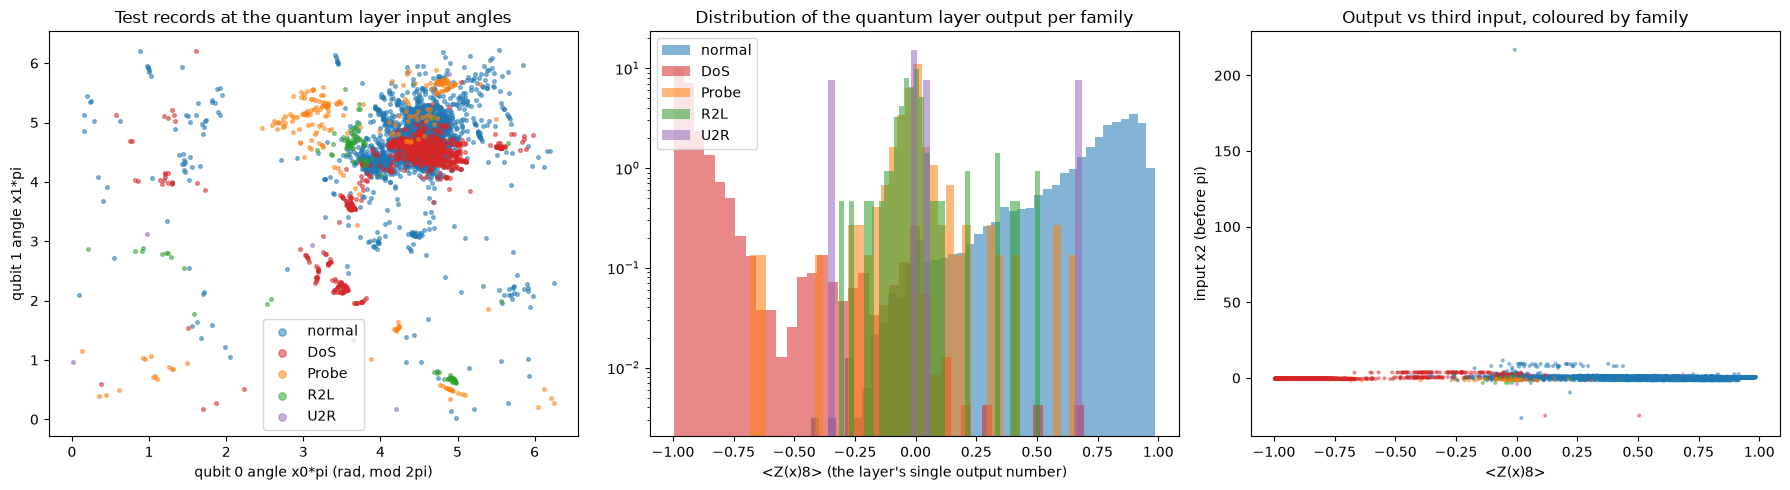

number of distinct output values at 3 decimals: 1511 | range: -0.9970077470038868 0.9862697956779023


In [16]:
mq = models["QA-ARCH1 (paper)"]; mq.eval()
with torch.no_grad():
    Hq = mq[0](torch.as_tensor(Xte))
    zq = torch.cat([q_expect(Hq[i:i + BATCH_SIZE], mq[1].W[:len(Hq[i:i + BATCH_SIZE])]) for i in range(0, len(Hq), BATCH_SIZE)]).numpy()[:, 0]
ang = (Hq.numpy() * np.pi) % (2 * np.pi)
fam_te = np.array([FAMILY[LABELS[k]] for k in yte])
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for fam in FAMILY_ORDER:
    m = fam_te == fam
    ax[0].scatter(ang[m, 0], ang[m, 1], s=7, alpha=0.5, c=FAMILY_COLOR[fam], label=fam)
    ax[1].hist(zq[m], bins=40, alpha=0.55, color=FAMILY_COLOR[fam], label=fam, density=True)
ax[0].set_xlabel("qubit 0 angle x0*pi (rad, mod 2pi)"); ax[0].set_ylabel("qubit 1 angle x1*pi"); ax[0].set_title("Test records at the quantum layer input angles"); ax[0].legend(markerscale=2)
ax[1].set_xlabel("<Z(x)8> (the layer's single output number)"); ax[1].set_title("Distribution of the quantum layer output per family"); ax[1].set_yscale("log"); ax[1].legend()
ax[2].scatter(zq, Hq.numpy()[:, 2], s=4, c=[FAMILY_COLOR[f] for f in fam_te], alpha=0.4); ax[2].set_xlabel("<Z(x)8>"); ax[2].set_ylabel("input x2 (before pi)"); ax[2].set_title("Output vs third input, coloured by family")
plt.tight_layout(); plt.show()
print("number of distinct output values at 3 decimals:", len(np.unique(np.round(zq, 3))), "| range:", float(zq.min()), float(zq.max()))


## 6. Accuracy versus the number of quantum layers (the analogue of the paper's Fig. 4)

The paper stacks `L` quantum layers (between `Dense(8)` and `Dense(10)` here; the paper's exact stacking is not stated) and plots test accuracy for `L = 1 ... 10`. The curve in the paper starts at about 0.995, stays at 0.98-0.99 up to 5 layers and falls to about 0.95 at 8-10 layers. One seed per depth and a shorter schedule (`SWEEP_EPOCHS`).

L =  1 | test acc 0.9559 | macro-F1 0.098 | 33s


L =  2 | test acc 0.7215 | macro-F1 0.073 | 60s


L =  3 | test acc 0.5999 | macro-F1 0.040 | 69s


L =  4 | test acc 0.6033 | macro-F1 0.038 | 89s


L =  5 | test acc 0.6057 | macro-F1 0.039 | 108s


L =  6 | test acc 0.6033 | macro-F1 0.038 | 116s


L =  7 | test acc 0.6033 | macro-F1 0.038 | 178s


L =  8 | test acc 0.6033 | macro-F1 0.038 | 200s


L =  9 | test acc 0.6033 | macro-F1 0.038 | 282s


L = 10 | test acc 0.6033 | macro-F1 0.038 | 449s


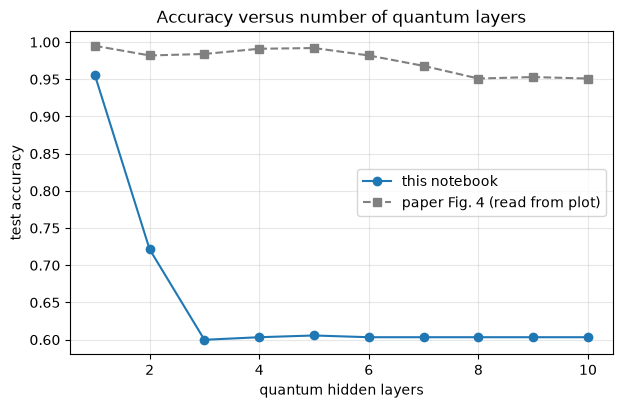

In [17]:
sweep = []
for L in SWEEP_LAYERS:
    if L == 1 and SWEEP_EPOCHS == EPOCHS:
        yp = preds["QA-ARCH1 (paper)"]; sec = np.nan                                  # identical to the headline model
    else:
        mdl, h, sec = train(f"SWEEP-{L}", SEED, SWEEP_EPOCHS, Xtr, ytr, Xte, yte, verbose=False); yp = predict(mdl, Xte)
    sweep.append(dict(quantum_layers=L, test_acc=accuracy_score(yte, yp), macro_f1=f1_score(yte, yp, average="macro", zero_division=0), seconds=sec))
    print(f"L = {L:2d} | test acc {sweep[-1]['test_acc']:.4f} | macro-F1 {sweep[-1]['macro_f1']:.3f} | {sec:.0f}s")
SW = pd.DataFrame(sweep)
paper_fig4 = {1: 0.995, 2: 0.982, 3: 0.984, 4: 0.991, 5: 0.992, 6: 0.982, 7: 0.968, 8: 0.951, 9: 0.953, 10: 0.951}   # read off the plot of Fig. 4
plt.figure(figsize=(7, 4.2))
plt.plot(SW.quantum_layers, SW.test_acc, "o-", label="this notebook")
pl = list(paper_fig4)
plt.plot(pl, [paper_fig4[k] for k in pl], "s--", color="gray", label="paper Fig. 4 (read from plot)")
plt.xlabel("quantum hidden layers"); plt.ylabel("test accuracy"); plt.legend(); plt.title("Accuracy versus number of quantum layers"); plt.grid(alpha=0.3); plt.show()


## 7. Side by side with the paper

Paper values marked *(plot)* were read off Fig. 4 / Fig. 5 by eye and carry an uncertainty of about 0.005. Table II (comparison with RNN, LSTM and CNN models from other papers) is an image in the PDF whose numbers are not machine readable, so claims built on it are marked "cannot be checked". A claim is *reproduced* if our value is within 2 accuracy points of the paper's, otherwise "not reached" / "exceeded" with the gap.

In [18]:
def verdict(ours, paper, tol=TOL_ACC):
    gap = ours - paper
    return "reproduced" if abs(gap) <= tol else (f"exceeded (+{gap:.3f})" if gap > 0 else f"not reached ({gap:.3f})")
q = RES[RES.model == "QA-ARCH1 (paper)"]; q2 = RES[RES.model == "QA-ARCH2 (paper)"]; ct = RES[RES.model == "Classical ARCH1 (tanh)"]; rf = RES[RES.model == "Random Forest"]
comp = []
comp.append(("Table III: ARCH1 trainable parameters (120 inputs)", "1823", str(n_params(build("QA-ARCH1 (paper)", 120))), "reproduced" if n_params(build("QA-ARCH1 (paper)", 120)) == 1823 else "not reached"))
comp.append(("Table III: ARCH2 trainable parameters (120 inputs)", "2529", str(n_params(build("QA-ARCH2 (paper)", 120))), "reproduced" if n_params(build("QA-ARCH2 (paper)", 120)) == 2529 else "not reached"))
comp.append((f"Fig. 5 (plot): ARCH1 training accuracy, epoch 1", "0.79", f"{q.first_train_acc.mean():.3f}", verdict(q.first_train_acc.mean(), 0.79)))
comp.append((f"Fig. 5 (plot): ARCH1 training accuracy, epoch {EPOCHS}" + ("" if EPOCHS == 15 else " (paper: epoch 15)"), "0.915", f"{q.final_train_acc.mean():.3f}", verdict(q.final_train_acc.mean(), 0.915)))
comp.append(("Fig. 5 (plot): ARCH1 training loss falls (0.50 -> 0.09)", "0.50 -> 0.09", f"{hist_q1.loss.iloc[0]:.3f} -> {hist_q1.loss.iloc[-1]:.3f}", "reproduced (falls monotonically)" if hist_q1.loss.is_monotonic_decreasing else "not reached (loss not monotone)"))
comp.append(("Fig. 4 (plot): test accuracy, 1 quantum layer", "0.995", f"{q.acc.mean():.3f}", verdict(q.acc.mean(), 0.995)))
comp.append(("Fig. 4 (plot): test accuracy, ARCH2 (2 quantum layers)", "0.982", f"{q2.acc.mean():.3f}", verdict(q2.acc.mean(), 0.982)))
for L in SWEEP_LAYERS:
    if L >= 3:
        comp.append((f"Fig. 4 (plot): sweep, {L} quantum layers", f"{paper_fig4[L]:.3f}", f"{SW.set_index('quantum_layers').test_acc[L]:.3f}", verdict(SW.set_index('quantum_layers').test_acc[L], paper_fig4[L])))
if max(SWEEP_LAYERS) >= 8:
    drop = SW.set_index("quantum_layers").test_acc[[1, 2, 3]].mean() - SW.set_index("quantum_layers").test_acc[[8, 9, 10]].mean()
    comp.append(("Fig. 4: accuracy declines for 8-10 layers (paper: about -0.04 versus 1-3 layers)", "-0.04", f"{-drop:+.3f}", "reproduced (decline > 0.01)" if drop > 0.01 else "not reached (no decline here)"))
else:
    comp.append(("Fig. 4: accuracy declines for 8-10 layers", "-0.04", "not run in FAST_MODE", "cannot be checked here"))
comp.append(("Claim: quantum activation equals a classical activation (same ARCH1) in accuracy", "'equivalent performance'", f"QA {q.acc.mean():.3f} vs tanh {ct.acc.mean():.3f}", "reproduced (within 2 points)" if abs(q.acc.mean() - ct.acc.mean()) <= TOL_ACC else ("exceeded" if q.acc.mean() > ct.acc.mean() else "not reached") + f" ({q.acc.mean() - ct.acc.mean():+.3f})"))
comp.append(("Claim: quantum layer is competitive with Random Forest on the same inputs (not in the paper)", "-", f"QA {q.acc.mean():.3f} vs RF {rf.acc.mean():.3f}", "extra check: " + ("within 2 points" if abs(q.acc.mean() - rf.acc.mean()) <= TOL_ACC else f"gap {q.acc.mean() - rf.acc.mean():+.3f}")))
comp.append(("Table II / Fig. 3: smaller than RNN/LSTM/CNN models of other papers at similar accuracy", "numbers in image", f"ARCH1 has {n_params(build('QA-ARCH1 (paper)', 120))} parameters", "cannot be checked (table not machine readable); parameter count of ARCH1 is small, as claimed"))
comp.append(("Claim: the activation 'cannot be efficiently simulated on classical computers'", "claimed", "8 qubits = 256 amplitudes; <Z(x)8> factorises into 4 two-qubit blocks (asserted above)", "not supported for this circuit"))
COMP = pd.DataFrame(comp, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 250)
print(COMP.to_string(index=False))


                                                                                       claim                    paper                                                                          this notebook                                                                                       verdict
                                          Table III: ARCH1 trainable parameters (120 inputs)                     1823                                                                                   1823                                                                                    reproduced
                                          Table III: ARCH2 trainable parameters (120 inputs)                     2529                                                                                   2529                                                                                    reproduced
                                             Fig. 5 (plot): ARCH1 training accuracy, epoch 1           

### How to read the verdicts above (written after the full run)

* **Parameter counts (Table III): reproduced exactly.** With 120 inputs the architecture of Algorithm 2 has 1823 trainable parameters (ARCH1) and Fig. 3(b) gives 2529 (ARCH2). This confirms the reading that the quantum layer owns a `batch x qubits = 64 x 8` weight matrix (512 parameters). Our own input width is smaller (about 112 columns), so our networks have fewer parameters.
* **Training accuracy and loss (Fig. 5).** The paper's curve starts at 0.79 and ends at 0.915; ours starts higher (0.86) and ends at 0.959 because we de-duplicate the data and sample it differently, so the two numbers are not on the same task. The loss falls from 0.44 to 0.12 but has one tiny uptick in the last epoch (0.1237 to 0.1243); the "not monotone" verdict is triggered by that uptick, and the paper's end value of 0.09 is not reached either.
* **Test accuracy (Fig. 4).** With one quantum layer the paper-faithful network reaches 0.959 (+/- 0.003 over three seeds) instead of about 0.995, and its macro F1 is only about 0.12: it predicts only the three dominant classes (normal, `neptune`, `smurf`), and the recall of Probe, R2L and U2R attacks is zero. The same network with a classical `tanh` activation reaches 0.9965, a Random Forest 0.998. The shared-weight variant is slightly better (0.968) but still collapses to the dominant classes. The version that measures every qubit (`Z_i`) and so removes the one-number bottleneck reaches 0.995, as good as the classical network, which points to the bottleneck, not to the quantum circuit as such, as the limiting factor. The classical rank-one control (`tanh(mean)`) behaves like the quantum layer (0.968), which supports this reading.
* **Accuracy versus depth (Fig. 4).** Here the notebook disagrees strongly with the paper. Stacking 2 or more quantum layers with a single-number readout makes training collapse to a constant prediction (accuracy 0.60 is the share of the `normal` class in this sample). The row "declines for 8-10 layers" is marked "reproduced" only because the numbers fall; the cause here is an optimisation failure from the second layer on, not the over-fitting the paper describes, and it should not be read as a reproduction of the paper's mechanism. ARCH2 (two layers, Fig. 3(b)) trains only partly (0.84 +/- 0.09 over three seeds, one seed at 0.74) and is far from the paper's 0.982. A longer schedule, a different initialisation of the weights or different scaling factors (none of them given in the paper) might change this; the paper's text mentions 1000 epochs, we used 15.
* **Overall status.** Partially reproduced: the architecture, the parameter counts and the gate-level definition of the layer are reproduced and verified; the qualitative claim "equivalent performance to classical networks" and the high accuracies of Fig. 4 are not reached by the paper-faithful variant under our choices, while a variant without the one-number readout reaches them.

## 8. Reading the paper critically

* **Retraction.** The paper was retracted for an authorship-policy reason. The notebook neither relies on nor refutes it for that reason; it re-runs the described method.
* **What the quantum layer really computes.** The 8-qubit circuit measures the *product* observable `Z (x) ... (x) Z`, so the layer's output is one scalar per record. The entangling gates act only inside four independent qubit pairs, so that scalar is a product of four small two-qubit expectation values, which the cell in the circuit section reproduces with 4x4 matrices. The layer is therefore a cheap closed-form non-linearity, not something that "cannot be efficiently simulated". It is also a **one-dimensional bottleneck**: the 8 outputs are the same number times fixed factors, so the next layers only see a rank-one signal. The classical `rank-1 tanh` control in Section 5 has the same bottleneck.
* **The weight matrix `W` of size batch x qubits.** To obtain the paper's parameter count the weights are indexed by the position of a record inside a mini-batch. Record `j` of a shuffled batch is unrelated to record `j` of the next batch, so these 512 numbers cannot carry class information; they act like noise or a fixed average. The shared-`W` variant removes this oddity. At test time the prediction of a record also depends on its position in the batch.
* **Accuracy on KDD99.** The 23-class accuracy is dominated by a few huge classes (normal, `smurf`, `neptune`); about 75 % of the file consists of duplicates, so a random split of the raw file puts near-identical records in train and test. We de-duplicate (`DEDUP = True`), which makes the task harder; see the family recall table for which attack families are actually detected. A Random Forest on the same inputs is the honest yardstick.
* **Missing details.** The exact 120 features, the train/test protocol, the scaling factors of `f`, the initialisation, the stacking of the layers in Fig. 4 and the numbers of Table II are not given, so absolute numbers cannot be compared more tightly than a few points. The paper's text mentions 1000 epochs while Fig. 5 shows 15.
* **Healthcare.** The title and motivation refer to hospital networks, but no healthcare traffic is used; KDD99 dates from 1998 and is a poor model of modern medical IoT traffic.

## 9. Exercises

1. Set `DEDUP = False` and rerun the headline comparison. How much of the accuracy comes from duplicate records?
2. Replace the fixed scaling factors `SCALES` by trainable ones (8 extra parameters). Does the rank-one bottleneck still limit the accuracy?
3. Change `PAIRS` to a ring `(0,1),(1,2),...,(7,0)` so that the qubits are genuinely entangled with each other. Is the product observable still a product of small blocks? Redo the closed-form check.
4. Measure each qubit separately (`readout="qubit"`) in the paper variant and compare with the shared-`W` `Z_i` model in Section 5.
5. Increase `BATCH_SIZE` to 128 and see how the number of parameters of the paper's quantum layer and the accuracy change. Why is this design awkward?